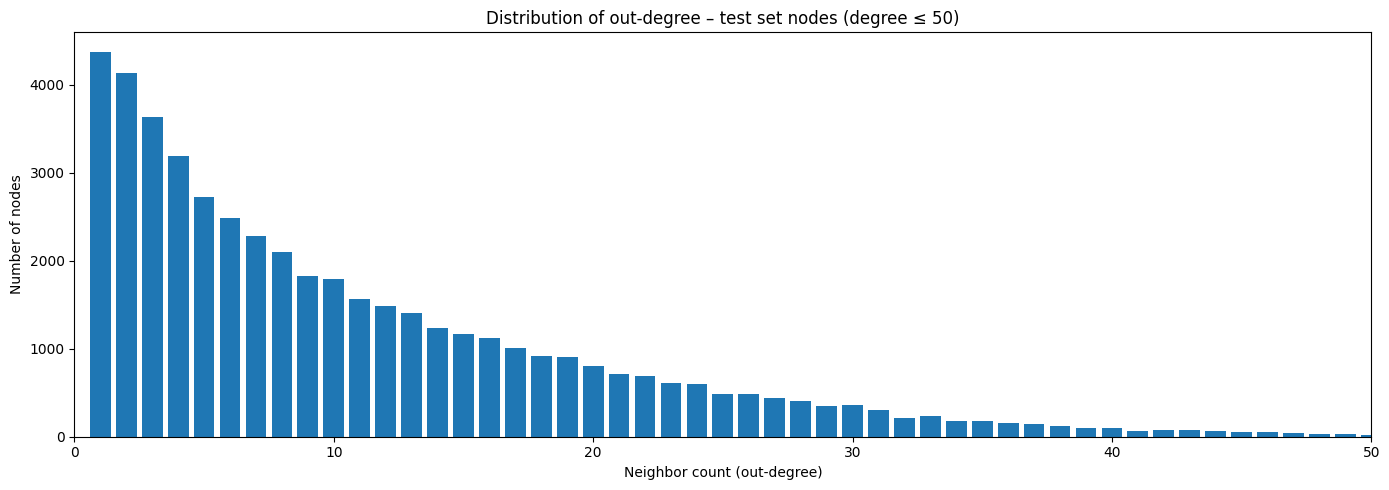

In [4]:
import json
import pandas as pd
import matplotlib.pyplot as plt

with open("./ogbn_arxiv_dataset/splits.json") as f:
    splits = json.load(f)
test_ids = set(splits["test"])

edges_df = pd.read_csv("./ogbn_arxiv_dataset/edges.csv")
test_edges = edges_df[edges_df["src_node_id"].isin(test_ids)]

neighbor_counts = test_edges.groupby("src_node_id").size()

count_dist = neighbor_counts.value_counts().sort_index()
count_dist = count_dist[count_dist.index <= 50]

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(count_dist.index, count_dist.values, width=0.8)
ax.set_xlabel("Neighbor count (out-degree)")
ax.set_ylabel("Number of nodes")
ax.set_title("Distribution of out-degree – test set nodes (degree ≤ 50)")
ax.set_xlim(0, 50)
plt.tight_layout()
plt.show()


In [6]:
# --- Fixed Cell: Full Dataset Node Count & Voyage Tokenization Estimates ---

# 1. Calculate the total number of unique nodes in the entire dataset
all_nodes_from_splits = set()
for split_name in splits:
    all_nodes_from_splits.update(splits[split_name])

max_node_id_edges = max(edges_df["src_node_id"].max(), edges_df["dst_node_id"].max()) + 1

total_nodes = max(len(all_nodes_from_splits), max_node_id_edges)
print(f"Total number of nodes in the FULL dataset: {total_nodes:,}")

# 2. Assumption and Estimation for Abstract ("ab strait") Tokenization
avg_words_per_abstract = 150 
avg_words_per_title = 12
total_words_per_paper = avg_words_per_title + avg_words_per_abstract

# Voyage AI / LLM tokenizers typically average ~1.3 tokens per word
tokens_per_word = 1.3
estimated_tokens_per_node = int(total_words_per_paper * tokens_per_word)
total_estimated_tokens = total_nodes * estimated_tokens_per_node

# Fixed: Removed commas so Python reads it as a float/int, not a tuple
cost_per_million_tokens = 0.06 
estimated_cost = (total_estimated_tokens / 1_000_000) * cost_per_million_tokens

print("\n--- Voyage AI Embedding Assumptions & Cost ---")
print(f"Assumed length per paper (Title + Abstract): {total_words_per_paper} words")
print(f"Estimated tokens per node: {estimated_tokens_per_node} tokens") # Fixed variable name
print(f"Total tokens to embed full set: {total_estimated_tokens:,} tokens")
print(f"Estimated Voyage AI Cost (at $0.06/M tokens): ${estimated_cost:.2f}")

Total number of nodes in the FULL dataset: 169,343

--- Voyage AI Embedding Assumptions & Cost ---
Assumed length per paper (Title + Abstract): 162 words
Estimated tokens per node: 210 tokens
Total tokens to embed full set: 35,562,030 tokens
Estimated Voyage AI Cost (at $0.06/M tokens): $2.13


In [2]:
import json
import pandas as pd

with open("./ogbn_arxiv_dataset/splits.json") as f:
    splits = json.load(f)
test_ids = set(splits["test"])

edges_df = pd.read_csv("./ogbn_arxiv_dataset/edges.csv")
nodes_df = pd.read_csv("./ogbn_arxiv_dataset/nodes.csv")

# Out-degree for every node that has at least one outgoing edge
all_out_degree = edges_df.groupby("src_node_id").size().rename("num_of_neighbors")

# Build a frame of test nodes with their out-degree (0 if not in edges at all)
test_degree_df = pd.DataFrame({"node_id": list(test_ids)})
test_degree_df = test_degree_df.join(all_out_degree, on="node_id")
test_degree_df["num_of_neighbors"] = test_degree_df["num_of_neighbors"].fillna(0).astype(int)

# Keep only degrees 1-20 and sample up to 10 per group
filtered = test_degree_df[(test_degree_df["num_of_neighbors"] >= 1) & (test_degree_df["num_of_neighbors"] <= 20)]
sampled = (
    filtered.groupby("num_of_neighbors", group_keys=False)
    .apply(lambda g: g.sample(min(len(g), 10), random_state=42))
    .reset_index(drop=True)
)

sampled_node_ids = set(sampled["node_id"])

# Edges where src is a sampled node
edges_subset = edges_df[edges_df["src_node_id"].isin(sampled_node_ids)].copy()

# All nodes to include: sampled + their neighbours
all_subset_ids = sampled_node_ids | set(edges_subset["dst_node_id"])

# Build single nodes CSV with is_test flag
nodes_subset = (
    nodes_df[nodes_df["node_id"].isin(all_subset_ids)][["node_id", "mag_id", "title", "abstract"]]
    .copy()
    .join(all_out_degree, on="node_id")
)
nodes_subset["num_of_neighbors"] = nodes_subset["num_of_neighbors"].fillna(0).astype(int)
nodes_subset["is_test"] = nodes_subset["node_id"].isin(sampled_node_ids).astype(int)
nodes_subset = nodes_subset.sort_values("node_id").reset_index(drop=True)

# Save
nodes_subset.to_csv("./ogbn_arxiv_dataset/nodes_subset.csv", index=False)
edges_subset.to_csv("./ogbn_arxiv_dataset/edges_subset.csv", index=False)

print(f"Sampled test nodes : {len(sampled_node_ids)}")
print(f"Neighbour nodes    : {len(all_subset_ids) - len(sampled_node_ids)}")
print(f"Total nodes saved  : {len(nodes_subset)}")
print(f"Edges saved        : {len(edges_subset)}")
print(f"Degree groups      : {sorted(sampled['num_of_neighbors'].unique())}")


Sampled test nodes : 200
Neighbour nodes    : 1736
Total nodes saved  : 1936
Edges saved        : 2100
Degree groups      : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_75597/1736925250.py:23: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), 10), random_state=42))


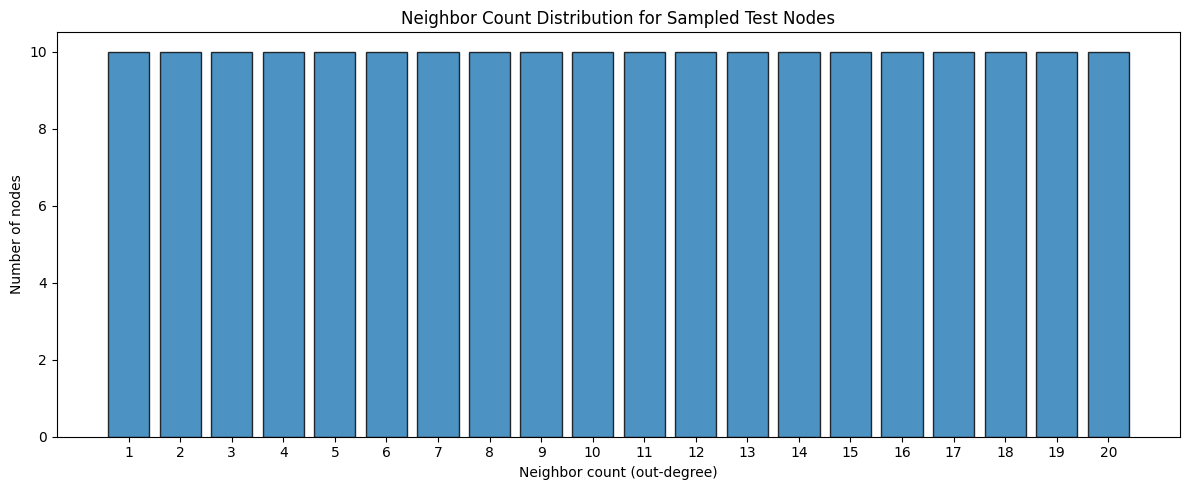

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the subset nodes dataset
file_path = "./ogbn_arxiv_dataset/nodes_subset.csv"
nodes_subset = pd.read_csv(file_path)

# 2. Filter using the boolean flag for test nodes
test_nodes = nodes_subset[nodes_subset["is_test"] == 1]

# 3. Calculate the distribution of the neighbor counts
degree_counts = test_nodes["num_of_neighbors"].value_counts().sort_index()

# 4. Create the bar chart
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(degree_counts.index, degree_counts.values, width=0.8, edgecolor="black", alpha=0.8)

# 5. Format the chart for clarity
ax.set_xlabel("Neighbor count (out-degree)")
ax.set_ylabel("Number of nodes")
ax.set_title("Neighbor Count Distribution for Sampled Test Nodes")

# Force x-ticks to show all degrees from 1 to 20 for readability
ax.set_xticks(range(1, 21)) 

plt.tight_layout()
plt.show()